# Pose estimation (DeepLabCut)

This notebook reviews the pose estimation stream of one converted session. The source is the
DeepLabCut output for each video (`videos/MetaSession{N}DLC_resnet50_J20_FVBApr30shuffle1_700000.h5`),
produced by a single-animal ResNet-50 model that tracks 11 body parts. In NWB it is stored with the
ndx-pose extension.

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import ndx_pose  # noqa: F401
import numpy as np
import pandas as pd
from hdmf.container import Container
from pynwb import NWBHDF5IO

In [2]:
nwb_file_path = Path("~/conversion_nwb/palop-lab-to-nwb/sub-63_ses-MetaSession3.nwb").expanduser()
dlc_file_path = Path(
    "/Volumes/seagate_0/vame/J20/videos/MetaSession3DLC_resnet50_J20_FVBApr30shuffle1_700000.h5"
)

io = NWBHDF5IO(nwb_file_path, "r")
nwbfile = io.read()
pose_estimation = nwbfile.processing["behavior"]["PoseEstimationDeepLabCut"]
skeleton = pose_estimation.skeleton
bodyparts = list(skeleton.nodes[:])

## NWB objects for this stream

In [3]:
summary = pd.DataFrame(
    [
        dict(
            name=neurodata_object.name,
            neurodata_type=neurodata_object.neurodata_type,
            namespace=neurodata_object.namespace,
            parent=neurodata_object.parent.name,
        )
        for neurodata_object in nwbfile.objects.values()
        if isinstance(neurodata_object, Container) and neurodata_object.parent is not None
    ]
)
stream_object_names = ["PoseEstimationDeepLabCut", "Skeletons", "Skeleton", "Camera3", *bodyparts]
summary[summary["name"].isin(stream_object_names)]

,name,neurodata_type,namespace,parent
1,Camera3,Device,core,root
3,Skeletons,Skeletons,ndx-pose,behavior
4,Skeleton,Skeleton,ndx-pose,Skeletons
52,PoseEstimationDeepLabCut,PoseEstimation,ndx-pose,behavior
53,Tailtip,PoseEstimationSeries,ndx-pose,PoseEstimationDeepLabCut
54,Tailbase,PoseEstimationSeries,ndx-pose,PoseEstimationDeepLabCut
55,Sternum,PoseEstimationSeries,ndx-pose,PoseEstimationDeepLabCut
56,Pelvis,PoseEstimationSeries,ndx-pose,PoseEstimationDeepLabCut
57,Nose,PoseEstimationSeries,ndx-pose,PoseEstimationDeepLabCut
58,Midtail,PoseEstimationSeries,ndx-pose,PoseEstimationDeepLabCut


Pose estimates should use ndx-pose: one `PoseEstimation` container in the `behavior` processing module
holding a `PoseEstimationSeries` per body part, a `Skeleton` (in `Skeletons`) linked to the subject, a
link to the camera `Device`, and a `source_video` link to the `BehaviorVideo` `ImageSeries`.

In [4]:
print("description:", pose_estimation.description)
print("source_software:", pose_estimation.source_software)
print("scorer:", pose_estimation.scorer)
print("device:", pose_estimation.device.name)
print("source_video:", pose_estimation.source_video.name)
print("skeleton:", skeleton.name, "| subject:", skeleton.subject.subject_id)
print("nodes:", bodyparts)
print("edges:", [[bodyparts[a], bodyparts[b]] for a, b in skeleton.edges[:]])

description: 2D keypoints estimated with DeepLabCut (ResNet-50, iteration 0, shuffle 1, snapshot 700000). Train error 2.06 px and test error 8.53 px (4.68 px with p-cutoff 0.6).
source_software: DeepLabCut
scorer: DLC_resnet50_J20_FVBApr30shuffle1_700000
device: Camera3
source_video: BehaviorVideo
skeleton: Skeleton | subject: 63
nodes: ['Nose', 'FLPaw', 'FRPaw', 'BLPaw', 'BRPaw', 'Sternum', 'Belly', 'Pelvis', 'Tailbase', 'Midtail', 'Tailtip']
edges: [['Nose', 'FLPaw'], ['FLPaw', 'FRPaw']]


In [5]:
nose = pose_estimation.pose_estimation_series["Nose"]
print("unit:", nose.unit)
print("reference_frame:", nose.reference_frame)
print("confidence_definition:", nose.confidence_definition)
print("rate:", nose.rate, "Hz | starting_time:", nose.starting_time, "s | frames:", nose.data.shape[0])

unit: pixels
reference_frame: (0,0) is the top-left pixel of the video frame, with x increasing to the right and y increasing downward.
confidence_definition: Softmax output of the deep neural network.
rate: 30.0 Hz | starting_time: 0.0 s | frames: 108271


## Load all keypoints into a table

In [6]:
timestamps = pd.Index(nose.get_timestamps(), name="time")
keypoint_tables = {}
for bodypart in bodyparts:
    series = pose_estimation.pose_estimation_series[bodypart]
    keypoint_tables[bodypart] = pd.DataFrame(
        np.column_stack([series.data[:], series.confidence[:]]), columns=["x", "y", "likelihood"], index=timestamps
    )
pose = pd.concat(keypoint_tables, axis=1)
pose.head()

Nose                             FLPaw                         \
                   x          y likelihood           x           y likelihood   
time                                                                            
0.000000  613.187744  47.946598   0.999936  581.409058  112.276222   0.999765   
0.033333  612.341064  47.666775   0.999941  581.291138  112.116486   0.999789   
0.066667  611.760254  47.917294   0.999953  581.202515  112.188469   0.999820   
0.100000  611.677917  47.808723   0.999960  581.234741  112.149979   0.999815   
0.133333  611.272705  48.518925   0.999971  581.315796  112.153137   0.999796   

               FRPaw                             BLPaw  ...     Pelvis  \
                   x          y likelihood           x  ... likelihood   
time                                                    ...              
0.000000  568.325012  87.189575   0.999751  514.207520  ...   0.996472   
0.033333  568.594299  87.052292   0.999708  514.197021  ...   0.996500   
0.066667  568.640259  87.024391   0.999672  514.187866  ...   0.996526   
0.100000  568.743042  86.992943   0.999645  514.175354  ...   0.996527   
0.133333  568.816345  86.993713   0.999667  514.191162  ...   0.996534   

            Tailbase                            Midtail              \
                   x           y likelihood           x           y   
time                                                                  
0.000000  455.775787  187.477386   0.999986  411.156647  254.043533   
0.033333  455.790222  187.464966   0.999986  411.174927  254.000259   
0.066667  455.868896  187.459564   0.999986  411.156097  254.028503   
0.100000  455.766449  187.387222   0.999986  411.316498  253.729446   
0.133333  455.801147  187.340729   0.999986  411.248474  253.901489   

                        Tailtip                         
         likelihood           x           y likelihood  
time                                                    
0.000000   0.999671  368.768768  335.629486   0.999991  
0.033333   0.999670  368.765106  335.625305   0.999991  
0.066667   0.999669  368.765808  335.626129   0.999991  
0.100000   0.999663  368.690063  335.844574   0.999992  
0.133333   0.999673  368.770386  335.626495   0.999992  

[5 rows x 33 columns]

## Keypoint coordinates over one minute

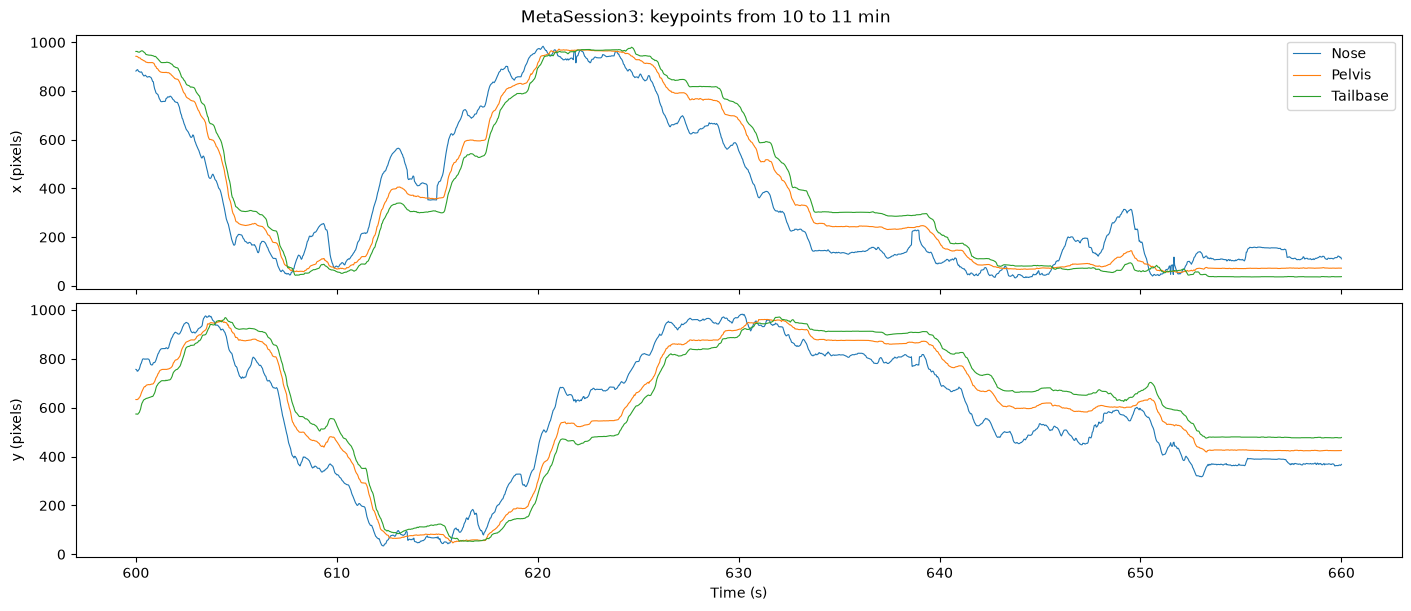

In [7]:
window = pose.loc[600:660]
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True, constrained_layout=True)
for bodypart in ["Nose", "Pelvis", "Tailbase"]:
    axes[0].plot(window.index, window[(bodypart, "x")], label=bodypart, linewidth=0.8)
    axes[1].plot(window.index, window[(bodypart, "y")], label=bodypart, linewidth=0.8)
axes[0].set_ylabel("x (pixels)")
axes[1].set_ylabel("y (pixels)")
axes[1].set_xlabel("Time (s)")
axes[0].legend(loc="upper right")
fig.suptitle(f"{nwbfile.session_id}: keypoints from 10 to 11 min")
plt.show()

## Confidence per body part

The fraction of frames above the p-cutoff used in the DLC evaluation (0.6).

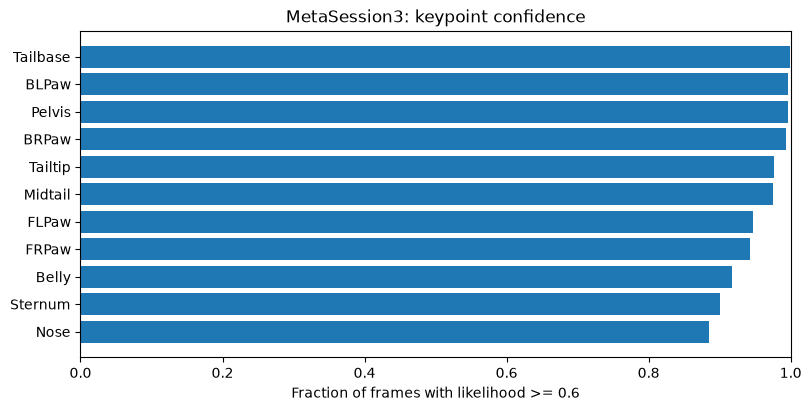

In [8]:
likelihood = pose.xs("likelihood", axis=1, level=1)
fraction_confident = (likelihood >= 0.6).mean().sort_values()

fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
ax.barh(fraction_confident.index, fraction_confident.values)
ax.set_xlim(0, 1)
ax.set_xlabel("Fraction of frames with likelihood >= 0.6")
ax.set_title(f"{nwbfile.session_id}: keypoint confidence")
plt.show()

## Keypoints over a video frame

In [9]:
def read_frame(video_path: Path, frame_index: int):
    capture = cv2.VideoCapture(str(video_path))
    capture.set(cv2.CAP_PROP_POS_FRAMES, frame_index)
    success, frame = capture.read()
    capture.release()
    if not success:
        raise IOError(f"Could not read frame {frame_index} from {video_path}.")
    return cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

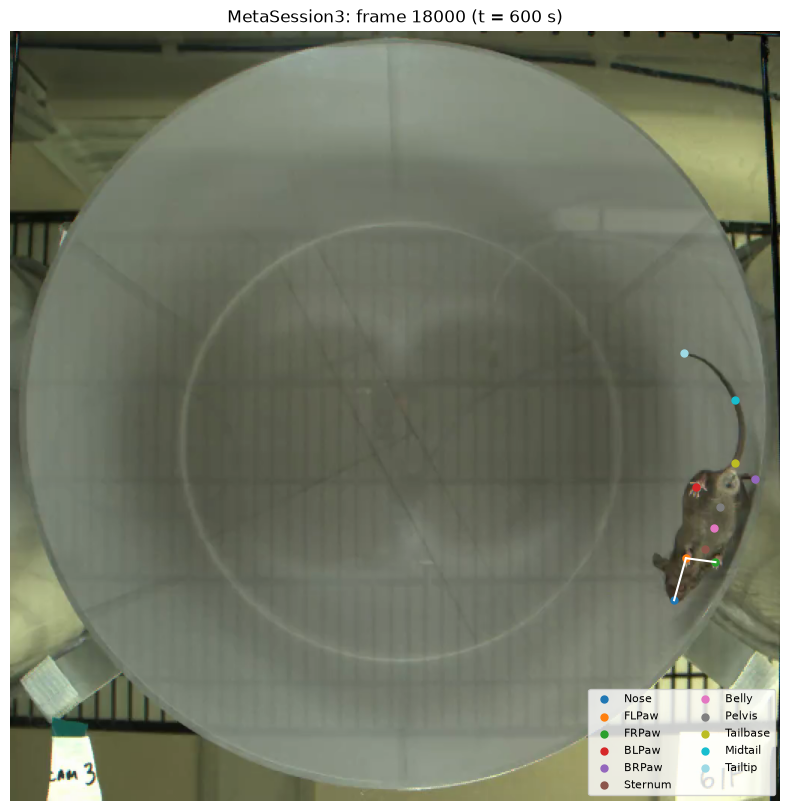

In [10]:
behavior_video = pose_estimation.source_video
video_path = nwb_file_path.parent / behavior_video.external_file[0]
frame_index = 18_000
frame_pose = pose.iloc[frame_index]

colors = plt.cm.tab20(np.linspace(0, 1, len(bodyparts)))

fig, ax = plt.subplots(figsize=(8, 8), constrained_layout=True)
ax.imshow(read_frame(video_path, frame_index))
for a, b in skeleton.edges[:]:
    ax.plot(
        [frame_pose[(bodyparts[a], "x")], frame_pose[(bodyparts[b], "x")]],
        [frame_pose[(bodyparts[a], "y")], frame_pose[(bodyparts[b], "y")]],
        color="white",
        linewidth=1.5,
    )
for bodypart, color in zip(bodyparts, colors):
    ax.scatter(frame_pose[(bodypart, "x")], frame_pose[(bodypart, "y")], s=25, color=color, label=bodypart)
ax.legend(loc="lower right", fontsize=8, ncols=2)
ax.set_title(f"{nwbfile.session_id}: frame {frame_index} (t = {frame_index / nose.rate:.0f} s)")
ax.axis("off")
plt.show()

## Check against the source file

Every coordinate and likelihood in NWB should equal the DeepLabCut output, frame by frame.

In [11]:
dlc_output = pd.read_hdf(dlc_file_path)
dlc_output.columns = dlc_output.columns.droplevel("scorer")
for bodypart in bodyparts:
    series = pose_estimation.pose_estimation_series[bodypart]
    assert np.array_equal(series.data[:], dlc_output[bodypart][["x", "y"]].to_numpy())
    assert np.array_equal(series.confidence[:], dlc_output[bodypart]["likelihood"].to_numpy())
print(f"All {len(bodyparts)} keypoints match the source for {len(dlc_output)} frames.")

All 11 keypoints match the source for 108271 frames.


In [12]:
io.close()